# Lithium-Ion Cell Impedance Relaxation Spectrum


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`frequency`，shape `(1, 107)`，dtype `<f8`：Measured frequency in Hz, native descending acquisition order.；`impedance`，shape `(1, 107)`，dtype `<c16`：Complex voltage/current ratio in ohm, real and imaginary components retained.。未知量为非负弛豫时间电阻谱gamma、串联R/L及拟合复阻抗。

获取模型：R+iωL+gamma/(1+iωtau)的log-tau积分产生阻抗谱。

如何恢复：src.solvers.solve/reconstruct：PWL求积+一阶差分正则化的非负逆解。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell9两组完整Nyquist/Bode观测及谱、残差、正则化敏感性。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。DRT是时间尺度分布而非空间物体图。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer a nonnegative relaxation-time resistance spectrum together with series resistance and inductance from one measured lithium-ion-cell impedance curve. Overlapping relaxation kernels and finite frequency coverage make the spectrum nonunique without regularization.

Recover a nonnegative electrochemical relaxation spectrum, series resistance and inductance from measured lithium-ion-cell impedance whose overlapping processes are poorly resolved in frequency.

This maintainer notebook actively reconstructs the complete bound observations with local numerical modules. It distinguishes the independently reproduced original method from fresh cleaned results. There is no cache-preview path. The paper describes the selected model; the exact bound dataset and modern port have separate provenance.

### Observation and inverse problem

Let Z(f) be complex impedance in ohms at positive frequency f in Hz. The passive relaxation model is

$$
Z(f)=R+\mathrm{i}2\pi f L+\int_{\ln\tau_{\min}}^{\ln\tau_{\max}}\frac{\gamma(\tau)}{1+\mathrm{i}2\pi f\tau}\,d\ln\tau+\epsilon(f).
$$

Here R is series resistance (ohm), L is series inductance (H), tau is relaxation time (s), gamma is a nonnegative resistance density per logarithmic time interval (ohm), i is the imaginary unit, and epsilon is measurement/model error. Finite bandwidth and similar responses from nearby relaxation times make the inversion ill-conditioned.

The acquisition is the complete 107-point author-deposited lithium-ion-cell spectrum. Recover the sampled relaxation spectrum and both series quantities on the supplied physical scale. No object truth or electrochemical reaction assignment is assumed.


## 2. Data

The complete author-deposited 107-point complex spectrum is retained on its physical scale. Frequency is Hz, complex impedance is ohm, relaxation time is seconds and inductance is H. No independent chemical-process spectrum or object truth is supplied.

The input is `data/raw_data.npz`; all arrays include batch size one.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| `frequency` | `(1, 107)` | `float64` | Measured frequency in Hz, native descending acquisition order. |
| `impedance` | `(1, 107)` | `complex128` | Complex voltage/current ratio in ohm, real and imaginary components retained. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Time convention | exp(+i 2π f t) | 1 | Passive capacitive response has negative imaginary impedance |
| Relaxation grid | tau[j] = 1 / frequency[j] | s | Ascending logarithmic nodes; preserve all 107 stored frequencies |
| Quadrature | Trapezoidal in ln(tau) | 1 | Half-width endpoint weights |
| Acquisition extent | 0.00500083202 to 999.040405 | Hz | Native measured frequencies; not rounded for computation |
| Input noise | Not calibrated | ohm | No Gaussian noise variance supplied |
| Boundary | Zero spectrum outside declared time interval | 1 | Finite-bandwidth inverse model |


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import make_figures,relative_error
data=load_data()
display(Markdown('| Observation | Internal shape | Dtype |\n| --- | --- | --- |\n'+'\n'.join(f'| {k} | {v.shape} | {v.dtype} |' for k,v in data.items())))

| Observation | Internal shape | Dtype |
| --- | --- | --- |
| frequency | (107,) | float64 |
| impedance | (107,) | complex128 |

## 3. Physics

The passive impedance integral below separates the frequency-independent series resistance, positive-imaginary inductive response and distributed relaxation kernel. Nyquist minus-imaginary plotting is a display convention; it must not change the forward model or submitted complex sign.

Let Z(f) be complex impedance in ohms at positive frequency f in Hz. The passive relaxation model is

$$
Z(f)=R+\mathrm{i}2\pi f L+\int_{\ln\tau_{\min}}^{\ln\tau_{\max}}\frac{\gamma(\tau)}{1+\mathrm{i}2\pi f\tau}\,d\ln\tau+\epsilon(f).
$$

Here R is series resistance (ohm), L is series inductance (H), tau is relaxation time (s), gamma is a nonnegative resistance density per logarithmic time interval (ohm), i is the imaginary unit, and epsilon is measurement/model error. Finite bandwidth and similar responses from nearby relaxation times make the inversion ill-conditioned.

The acquisition is the complete 107-point author-deposited lithium-ion-cell spectrum. Recover the sampled relaxation spectrum and both series quantities on the supplied physical scale. No object truth or electrochemical reaction assignment is assumed.


## 4. Method

The implemented PWL discretization uses log-time quadrature, adjacent first-difference ridge regularization and nonnegative augmented-system NNLS. CVXOPT belongs only to the independent oracle comparison, with its tightened stopping tolerances explicitly preserved.

### Implemented mathematics and numerical conventions

The selected implementation is the PWL option of the published ridge-regularized DRT method, not the Gaussian-RBF option. There are N=107 frequency samples f_i, tau_j=1/f_j and u_j=ln(tau_j). Quadrature weights are w_0=(u_1-u_0)/2, w_(N-1)=(u_(N-1)-u_(N-2))/2 and w_j=(u_(j+1)-u_(j-1))/2 otherwise. A_ij=w_j/(1+i 2π f_i tau_j). The complete design B has columns [i2πf,1,A]; x=[L,R,gamma]. All unknowns are constrained nonnegative.

The exact objective is ||Re(Bx-z)||²+||Im(Bx-z)||²+lambda||Dx||², with no division by sample count and no factor one-half. lambda=1e-3. D ignores L,R and has adjacent entries [-1/delta_j,+1/delta_j], delta_j=ln(tau_j/tau_(j+1)); the author's opposite sign convention to increasing log-time cancels in DᵀD and is preserved. Solve the explicitly augmented real system [Re B;Im B;sqrt(lambda)D]x≈[Re z;Im z;0] using general-purpose scipy.optimize.nnls, maxiter=10000. NNLS uses its active-set initialization/stopping; there is no custom line search or arbitrary iteration loop.

The independent oracle solves the identical nonnegative quadratic program with CVXOPT. Its first numerical stopping settings left a small positive barrier in near-zero gamma coefficients; tightening oracle absolute tolerance to 1e-18, relative tolerance to 1e-15, feasibility tolerance to 1e-14, maxiters=200 reconciled the two optimizers without changing lambda, model or acceptance tolerance. The unconstrained posterior mean stored internally by upstream is not its published nonnegative output and is not used as reference.

Evaluate complex residuals in ohm. Plot Nyquist minus-imaginary values only for display; submitted arrays retain the original imaginary sign. No normalization, alignment or log conversion is applied by Judge.


## 5. Results

The preserved active path reconstructs every required quantity, runs the standalone Judge and computes complete Nyquist, spectrum and robustness comparisons. Method-reference agreement and measured impedance residuals answer different questions; reduced-frequency studies change the quadrature grid as well as the number of measurements.

### Fresh full reconstruction

The standard local path below computes every required output quantity from the bound public measurements and writes the declared submission. Runtime includes the complete reconstruction. Evaluation is a separate subprocess using the standalone Judge.

### Scientific comparisons and recomputed experiments

The reconstruction figure includes measured signal consistency and independently reproduced upstream comparison. The robustness figure recomputes its model/regularization and acquisition/calibration changes. Original arrays are comparison inputs only; every curve labeled fresh is computed here. Exact numerical trace arrays are returned for the separately archived figure exports.


In [2]:
start=time.perf_counter()
fresh=run()
solver_runtime_s=time.perf_counter()-start
judge_process=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8',env=dict(os.environ,PYTHONIOENCODING='utf-8'))
assert judge_process.returncode==0,judge_process.stderr
judge_report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['status']=='pass'
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
agreement={key:relative_error(fresh[key],reference[key]) for key in fresh}
print(json.dumps({'identity':'fresh cleaned full reconstruction','solver_runtime_s':solver_runtime_s,'upstream_relative_errors':agreement,'standalone_judge':judge_report},indent=2,allow_nan=False))

{
  "identity": "fresh cleaned full reconstruction",
  "solver_runtime_s": 0.0023652000818401575,
  "upstream_relative_errors": {
    "reconstruction": 3.781466348305186e-08,
    "series_parameters": 4.484547975810474e-13,
    "fitted_impedance": 1.1240218391688943e-10
  },
  "standalone_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_relative_error": 3.781466348305186e-08,
      "series_parameters_0_relative_error": 6.862926877696701e-12,
      "series_parameters_1_relative_error": 4.4845479631354764e-13,
      "fitted_impedance_relative_error": 1.1240218391688943e-10
    },
    "thresholds": {
      "reconstruction_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "series_parameters_0_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "series_parameters_1_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "fitted_impedance_relative

In [3]:
experiment_start=time.perf_counter()
figures,plot_trace,experiment_metrics=make_figures(data,fresh,reference)
plt.close('all')
experiment_runtime_s=time.perf_counter()-experiment_start
measurement={'identity':'fresh cleaned notebook reconstruction and actively recomputed comparisons','raw_data_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'solver_runtime_s':solver_runtime_s,'experiments_runtime_s':experiment_runtime_s,'upstream_relative_errors':agreement,'scientific_measurements':experiment_metrics,'judge':judge_report,'historical_paper_numbers_used':False}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False)+'\n',encoding='utf8')
print(json.dumps(experiment_metrics,indent=2,allow_nan=False))

{
  "upstream_relative_error": 3.781466348305186e-08,
  "observation_relative_error": 0.0017682761892180742,
  "regularization_scan": [
    [
      1e-05,
      0.00170674933576291,
      0.1956034749168365
    ],
    [
      0.001,
      0.002356519720803413,
      0.059156193717579596
    ],
    [
      0.1,
      0.006214965411548076,
      0.030221768268662647
    ]
  ],
  "series_L_H_R_ohm": [
    5.565693972469408e-07,
    0.11304496970197184
  ]
}


### Reconstruction

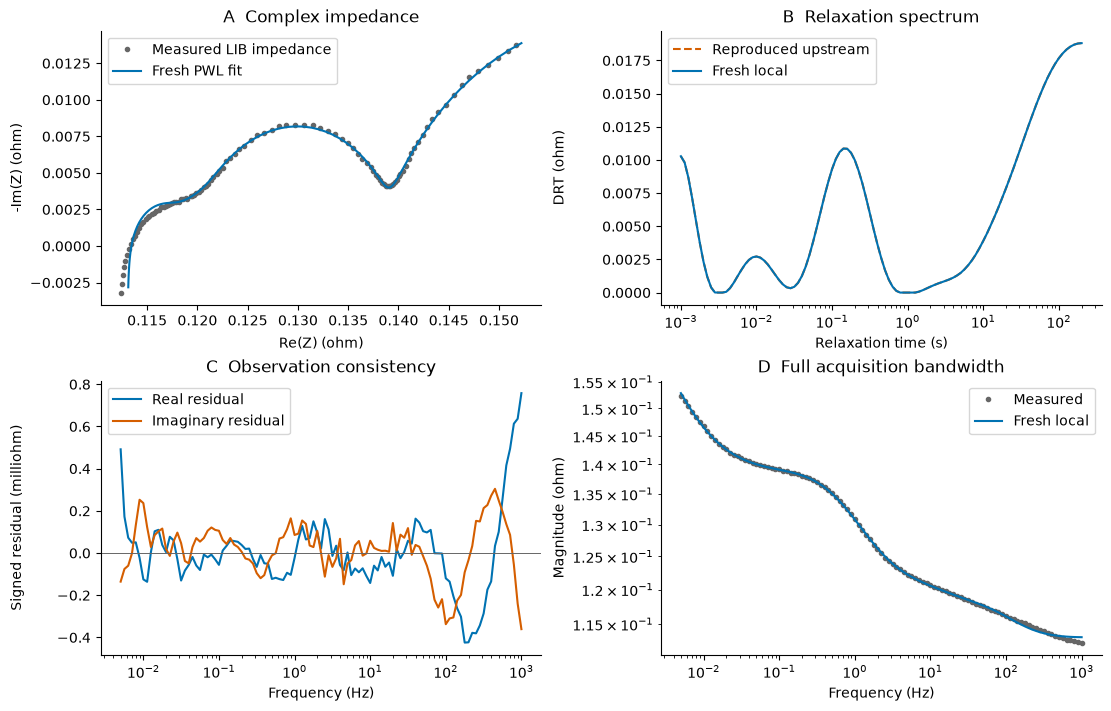

### Robustness

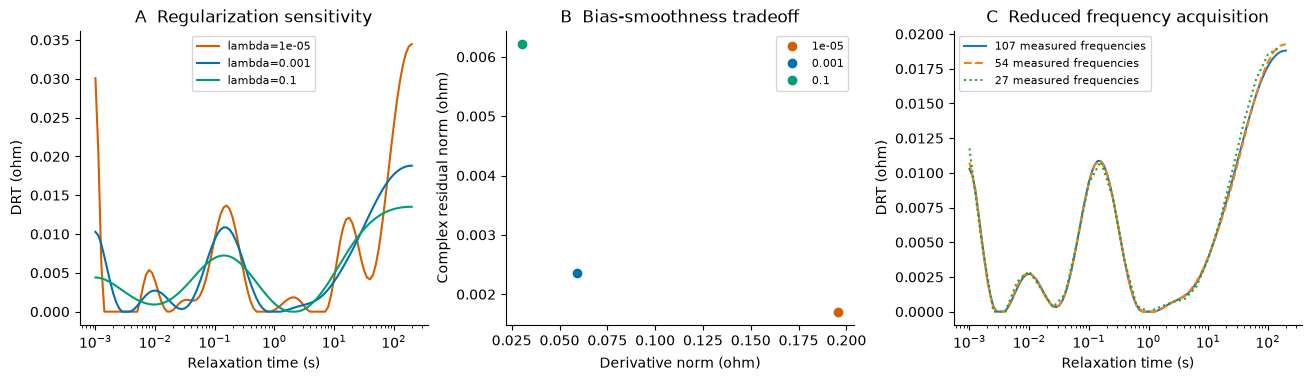

In [4]:
for figure_name,figure in figures.items():
    display(Markdown('### '+figure_name.replace('_',' ').title()))
    display(figure)
    plt.close(figure)

## 6. Conclusion

The retained comparisons support reproduction of the selected nonnegative PWL inverse. Boundary-adjacent long-time structure and penalty-dependent peaks cannot identify unique electrochemical reactions; no reconstructed spectrum is called ground truth.

### Interpretation and limitations

The nonnegative PWL spectrum explains the measured Nyquist curve, but the largest-time rise sits against the finite bandwidth edge and must not be assigned to a unique chemical process. The regularization sweep reveals additional peaks at low penalty and broader structure at high penalty. Reduced frequency acquisitions change the quadrature grid as well as the number of constraints; they are labeled as fresh reduced-acquisition studies.

Agreement with the standard method establishes implementation fidelity. Independent mathematical tests check operators and signs, while measured residuals and sensitivity studies bound physical interpretation. No reconstruction is relabeled as ground truth.

### Sources

Saccoccio et al., Optimal regularization in distribution of relaxation times applied to electrochemical impedance spectroscopy: ridge and lasso regression methods, Electrochimica Acta 147 (2014), 470–482. https://doi.org/10.1016/j.electacta.2014.09.058

Wan et al., Influence of the discretization methods on the distribution of relaxation times deconvolution, Electrochimica Acta 184 (2015), 483–499. https://doi.org/10.1016/j.electacta.2015.09.097
